In [ ]:
import json
import pandas as pd

# Load datasets
with open("train.json", "r") as f:
    train_data = json.load(f)

with open("test.json", "r") as f:
    test_data = json.load(f)

# Convert to DataFrames
train_df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)

# Display basic information
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nTraining samples:")
print(train_df.head())

print("\nClass distribution:")
print(train_df["label"].value_counts())

print("\nMissing values:")
print(train_df.isnull().sum())

Training dataset: (25000, 2)
Testing dataset: (25000, 2)

Training samples:
                                                text  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1

Class distribution:
label
1    12500
0    12500
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64


In [39]:
from sklearn.model_selection import train_test_split

X = train_df["text"]
y = train_df["label"]

x_train, x_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=34,
    stratify=y
)

x_test = test_df["text"]
y_test = test_df["label"]

print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Testing samples:", len(x_test))

Training samples: 20000
Validation samples: 5000
Testing samples: 25000


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# An error I made was using this Pipeline / Instead the GridSearchCV will tune these parameters
# model = Pipeline([
#     ("tfidf", TfidfVectorizer(
#         lowercase=True,
#         strip_accents="unicode",
#         ngram_range=(1, 2), # Considers individual words and pairs of consecutive words.
#         min_df=2, # remove words that appears less than twice
#         max_df=0.95, # remove words that appears more than 95%
#         sublinear_tf=True, # logarithmic scaling to balance frequency
#     )),

#     ("classifier", LogisticRegression(
#         C=1.0,
#         max_iter=1000,
#         solver="liblinear"
#     ))
# ])

model = Pipeline([
    ("vectorizer", TfidfVectorizer(sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [42]:
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


Accuracy: 0.8858
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.87      0.88      2500
           1       0.87      0.90      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000

ROC-AUC: 0.9572968000000001


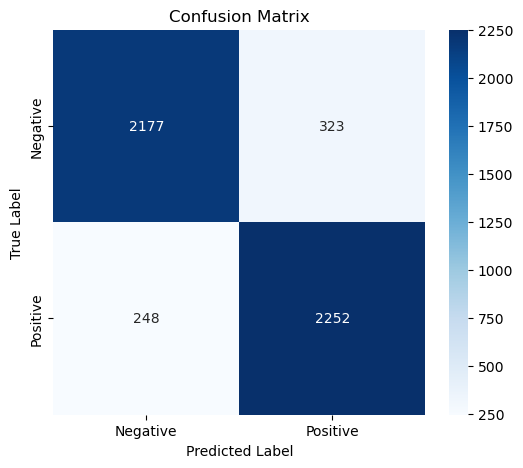

In [43]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(x_val)
y_proba = model.predict_proba(x_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Classification Report:\n", classification_report(y_val, y_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_proba))
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [44]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "vectorizer__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "vectorizer__min_df": [2, 5],
    "vectorizer__max_df": [0.8, 0.95],
    "classifier__C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=3,
    verbose=1
)

grid_search.fit(x_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'classifier__C': 10, 'vectorizer__max_df': 0.8, 'vectorizer__min_df': 2, 'vectorizer__ngram_range': (1, 2)}
Best CV accuracy: 0.9042999999999999


In [45]:
best_model = grid_search.best_estimator_

In [46]:
y_pred = best_model.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

y_proba = best_model.predict_proba(x_test)[:, 1]

print("\nROC-AUC:", roc_auc_score(y_test, y_proba))

Test Accuracy: 0.90208

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     12500
           1       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000


Confusion Matrix:
[[11246  1254]
 [ 1194 11306]]

ROC-AUC: 0.9648768384


In [ ]:
import joblib

joblib.dump(best_model, "model.joblib")

['skills_assessment.joblib']

In [ ]:
import joblib
loaded_model = joblib.load("model.joblib")
print(loaded_model)

reviews = [
    "This movie was absolutely fantastic!",
    "This movie was a complete waste of time."
]

print(loaded_model.predict(reviews))

Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(max_df=0.8, min_df=2, ngram_range=(1, 2),
                                 sublinear_tf=True)),
                ('classifier', LogisticRegression(C=10, max_iter=1000))])
[1 0]
